# Wanna make some Mass-Radius KDE's?
* [Simple KDE](#simple)
* [KDE + MARDIGRAS](#mardi) << the one you want

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
import seaborn as sns
import pandas as pd

## Simple KDE plot <a class="anchor" id="simple"></a>
- No background.
- No evolution lines.
- Nothing. Vanilla.

In [10]:
# load data


# # Parameters for the 2D Gaussian distributions
# mean1 = [2, 3]  # Mean of dataset 1 (x, y)
# cov1 = [[1, 0.5], [0.5, 1]]  # Covariance matrix for dataset 1

# mean2 = [5, 5]  # Mean of dataset 2 (x, y)
# cov2 = [[1, -0.5], [-0.5, 1]]  # Covariance matrix for dataset 2

# Number of samples to generate for each dataset
n_planets = 5000

M_e = 5.97237e24 #Earth mass (kg)
R_e = 6.371e6 #Earth radius (m)

# # Generate random 2D data from Gaussian distributions
# data1 = np.random.multivariate_normal(mean1, cov1, n_samples)
# data2 = np.random.multivariate_normal(mean2, cov2, n_samples)


# loop import planets starting and ending 
mp_start = np.array([])
rp_start = np.array([])
mp_end = np.array([])
rp_end = np.array([])

for i in range(n_planets):
    planetnum = i+1
    # import a planet's evolutionary track (just mp_gp and rp_gp)
    filename = f'./evolution-data/gp-evo/5000_xp_070925/planet_{planetnum}-{n_planets}_evolution_data.csv'
    mp_gp,rp_gp = np.loadtxt(filename,usecols=(1,2),unpack=True) #skiprows=1,
    
    # mp_s = mp_gp[0]
    # mp_e = mp_gp[-1]
    # rp_s = rp_gp[0]
    # rp_e = rp_gp[-1]

    mp_start = np.append(mp_start, mp_gp[0])
    rp_start = np.append(rp_start, rp_gp[0])
    mp_end = np.append(mp_end, mp_gp[-2])
    rp_end = np.append(rp_end, rp_gp[-2])

# # Extract x and y coordinates from the generated data
# mp_x, data1_y = start_points[:, 0], start_points[:, 1]
# data2_x, data2_y = data2[:, 0], data2[:, 1]

mp_start = mp_start/M_e
rp_start = rp_start/R_e
mp_end = mp_end/M_e
rp_end = rp_end/R_e


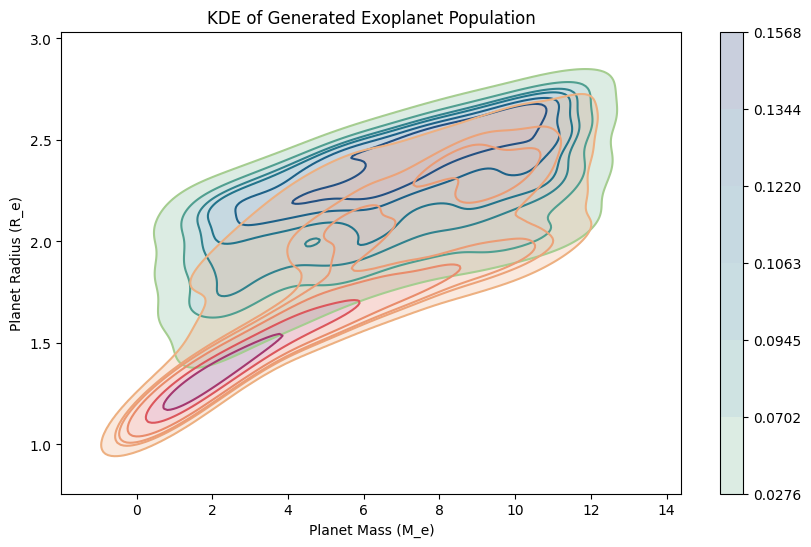

In [12]:
#composite
# Create the KDE plot
plt.figure(figsize=(10, 6))


i_color = sns.cm.crest
f_color = sns.cm.flare

# Plot KDE for Dataset 1
sns.kdeplot(x=mp_start*M_e, y=rp_start*R_e, cmap=i_color, levels=7)
sns.kdeplot(x=mp_start*M_e, y=rp_start*R_e, fill=True, \
            cmap=i_color, levels=7, label="Initial", alpha=0.25, cbar=True)

# Plot KDE for Dataset 2
sns.kdeplot(x=mp_end*M_e, y=rp_end*R_e, cmap=f_color, levels=7)
sns.kdeplot(x=mp_end*M_e, y=rp_end*R_e, fill=True, \
            cmap=f_color, levels=7, label="Final", alpha=0.25)#,cbar=True)



# # Plot KDE for start/end points
# sns.kdeplot(x=mp_start/M_e, y=rp_start/R_e, fill=True, cmap="GnBu", label="Evolution Start", alpha=0.5)

# sns.kdeplot(x=mp_end/M_e, y=rp_end/R_e, fill=True, cmap="RdPu", label="Evolution End", alpha=0.5)

# Add labels and title
plt.title("KDE of Generated Exoplanet Population")
plt.xlabel('Planet Mass (M_e)')
plt.ylabel('Planet Radius (R_e)')
# plt.grid(color='slategray', alpha=0.25)

# Save and show figure

filename = f'./plots/0709_population/{n_planets}_kde_plt_initfin.png'
# plt.savefig(f'./plots/gp-xp/5000_plots_070925/{filename}.png')
# print(f'\n  File saved: {os.getcwd()}/plots/gp-xp/5000_plots_070925/{filename}.png \n')
plt.show()



  File saved: /Users/emersontao/Desktop/waterworlds/plots/gp-xp/5000_plots_070925/5000_kde_plt_init.png 



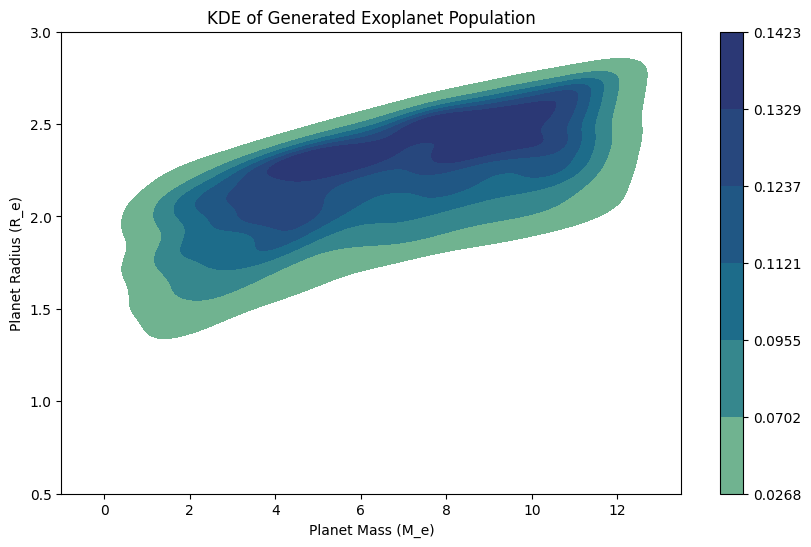


  File saved: /Users/emersontao/Desktop/waterworlds/plots/gp-xp/5000_plots_070925/5000_kde_plt_fin.png 



<Figure size 640x480 with 0 Axes>

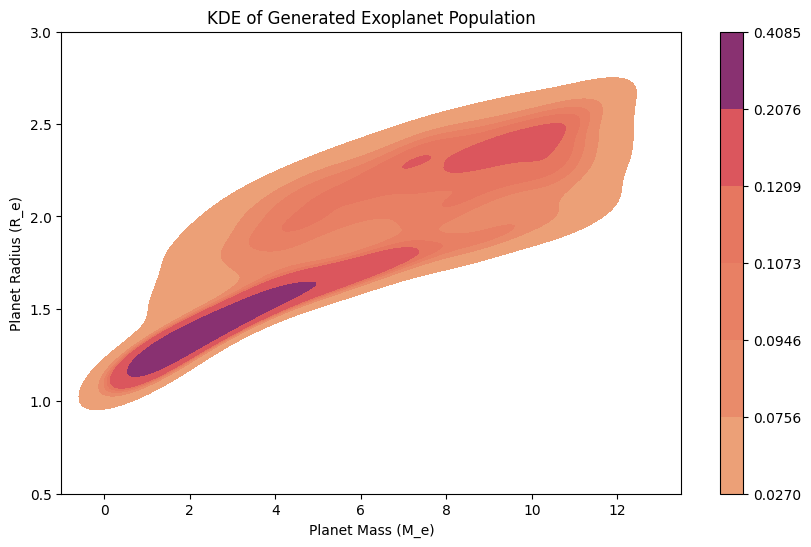

In [8]:
# Create the KDE plot

i_color = sns.cm.crest
f_color = sns.cm.flare


# Plot KDE for Dataset 1
plt.figure(figsize=(10, 6))

# sns.kdeplot(x=mp_start, y=rp_start, cmap=i_color, levels=7)
sns.kdeplot(x=mp_start, y=rp_start, fill=True,
            cmap=i_color, levels=7, label="Initial", cbar=True)


# # Plot KDE for start/end points
# sns.kdeplot(x=mp_start/M_e, y=rp_start/R_e, fill=True, cmap="GnBu", label="Evolution Start", alpha=0.5)

# sns.kdeplot(x=mp_end/M_e, y=rp_end/R_e, fill=True, cmap="RdPu", label="Evolution End", alpha=0.5)

# Add labels and title
plt.title("KDE of Generated Exoplanet Population")
plt.xlabel('Planet Mass (M_e)')
plt.ylabel('Planet Radius (R_e)')
plt.xlim(-1,13.5)
plt.ylim(0.5,3)
# plt.grid(color='slategray', zorder=-5, alpha=0.25)

# Save and show figure
filename = f'{n_planets}_kde_plt_init'
# plt.savefig(f'./plots/gp-xp/5000_plots_070925/{filename}.png')
print(f'\n  File saved: {os.getcwd()}/plots/gp-xp/5000_plots_070925/{filename}.png \n')
plt.show()
plt.clf()




# Plot KDE for Dataset 2

plt.figure(figsize=(10, 6))
# sns.kdeplot(x=mp_end, y=rp_end, cmap=f_color, levels=7)
sns.kdeplot(x=mp_end, y=rp_end, fill=True,
            cmap=f_color, levels=7, label="Final", cbar=True)

# # Plot KDE for start/end points
# sns.kdeplot(x=mp_start/M_e, y=rp_start/R_e, fill=True, cmap="GnBu", label="Evolution Start", alpha=0.5)

# sns.kdeplot(x=mp_end/M_e, y=rp_end/R_e, fill=True, cmap="RdPu", label="Evolution End", alpha=0.5)

# Add labels and title
plt.title("KDE of Generated Exoplanet Population")
plt.xlabel('Planet Mass (M_e)')
plt.ylabel('Planet Radius (R_e)')
plt.xlim(-1,13.5)
plt.ylim(0.5,3)
# plt.grid(color='slategray', zorder=-5, alpha=0.25)

# Save and show figure

filename = f'{n_planets}_kde_plt_fin'
# plt.savefig(f'./plots/gp-xp/5000_plots_070925/{filename}.png')
print(f'\n  File saved: {os.getcwd()}/plots/gp-xp/5000_plots_070925/{filename}.png \n')
plt.show()


## KDE + mardigras  <a class="anchor" id="mardi"></a>
- Now we're talking!
- Includes lines
- Includes MARDIGRAS background
- Actually useful for conveying information. Not vanilla.

Catalog updated successfully and saved to ./Models/catalog_exoplanets.dat


FileNotFoundError: ./evolution-data/gp-evo/5000_xp/planet_1-5000_evolution_data.csv not found.

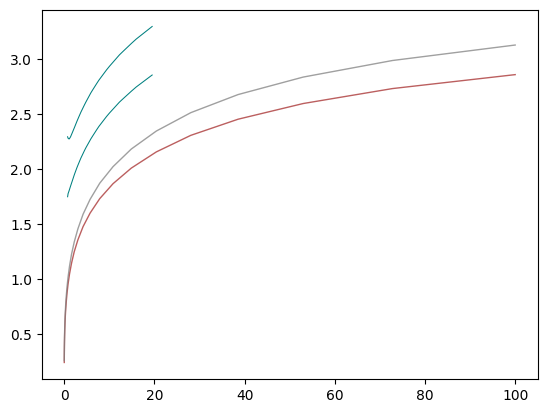

In [5]:
# KDE Plot for gpevo
# with MARDIGRAS background

# sns.set_theme(style="darkgrid")

# Number of samples to generate for each dataset
n_planets = 5000

M_e = 5.97237e24 #Earth mass (kg)
R_e = 6.371e6 #Earth radius (m)

# ------------------------------------------------ #
# EXOARCHIVE
# Straight from MARDIGRAS!

import argparse
import requests
from datetime import datetime
# Flag to update the catalog
# parser = argparse.ArgumentParser(description="Generate KDE plots with some of MARDIGRAS' features.")
# parser.add_argument(
#     "--update-nea-catalog",
#     action="store_true",
#     help="Update the NASA Exoplanet Archive catalog before starting the tool.",
# )

# Flag to choose another type of catalog
# parser.add_argument(
#     "--catalog",
#     choices=["NEA", "PlanetS"],
#     default="NEA",
#     help="Choose the exoplanet catalog to use. Default is NEA."
# )

catalog = 'PlanetS'
update_nea_catalog=True
# args = parser.parse_args()

# Exoplanet catalog

def check_internet_connection():
    """Check if there is internet access by pinging a known URL."""
    try:
        requests.get("https://www.google.com", timeout=5)
        return True
    except requests.ConnectionError:
        return False

def update_nea_exoplanet_catalog(catalog_url, output_file):
    """
    Updates the NEA exoplanet catalog from the NASA Exoplanet Archive TAP.
    Parameters:
        catalog_url (str): The TAP URL with the SQL query for the catalog.
        output_file (str): Path to save the downloaded catalog.
    """
    if not check_internet_connection():
        print("No internet connection. Unable to update the exoplanet catalog.")
        return

    try:
        response = requests.get(catalog_url, timeout=10)
        response.raise_for_status()  # Raise an error for HTTP issues
        
        # Prepare the header
        header = [
            "# NASA Exoplanet Catalog",
            f"# Source: {catalog_url}",
            f"# Catalog last updated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
        ]
        
        # Write the header and data to the file
        with open(output_file, "w") as f:
            f.write("\n".join(header) + "\n")
            # Add '#' to the parameter names
            data_lines = response.text.splitlines()
            f.write("# " + data_lines[0] + "\n")  # Add # to parameter names
            f.write("\n".join(data_lines[1:]) + "\n")
        
        print(f"Catalog updated successfully and saved to {output_file}")
    except requests.RequestException as e:
        print(f"Error fetching the catalog: {e}")

def read_nea_last_update(output_file):
    """
    Reads the date of the last update from the catalog file and prints it.
    Parameters:
        output_file (str): Path to the catalog file.
    """
    if not os.path.exists(output_file):
        print("Catalog file does not exist.")
        return

    try:
        with open(output_file, "r") as f:
            for line in f:
                if line.startswith("# Catalog last updated:"):
                    print(line.strip())
                    break
    except Exception as e:
        print(f"Error reading the catalog: {e}")

# File paths and URL of the NEA Catalog
nea_catalog_url = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync?"
               "query=select+pl_name,pl_rade,pl_radeerr1,pl_radeerr2,"
               "pl_masse,pl_masseerr1,pl_masseerr2,pl_eqt+from+ps+where+"
               "default_flag=1+and+pl_controv_flag=0+and+pl_rade+is+not+null+"
               "and+pl_masse+is+not+null+and+pl_bmassprov='Mass'&format=tsv")
nea_output_file = "./Models/catalog_exoplanets.dat"

if update_nea_catalog:
    # Update the catalog
    update_nea_exoplanet_catalog(nea_catalog_url, nea_output_file)
else:
    # Check for existing catalog and print the last update date
    read_nea_last_update(nea_output_file)

list_catalog_rp,list_catalog_rpe1,list_catalog_rpe2,list_catalog_mp,list_catalog_mpe1,list_catalog_mpe2 \
    = np.genfromtxt(nea_output_file,delimiter="\t",unpack=True,usecols=(1,2,3,4,5,6),filling_values=0.0)

# Load the exoplanet names
list_catalog_names = np.genfromtxt(
    nea_output_file, delimiter="\t", dtype=str, usecols=0
)

# This procedure removes planets that don't have radius and/or mass measurements
# the goal is to have arrays of smaller size, so that rendering is faster when sliders are used
list_exo_rp = []
list_exo_rpe1 = []
list_exo_rpe2 = []
list_exo_mp = []
list_exo_mpe1 = []
list_exo_mpe2 = []
list_exo_names = []
for i in range(len(list_catalog_rp)):
    exo_mass_prec = 0.5 # minimum precision on exoplanet mass
    if list_catalog_rp[i]!=0.0 and list_catalog_mp[i]!=0.0 \
        and (abs(list_catalog_mpe1[i]))/list_catalog_mp[i] < exo_mass_prec \
        and (abs(list_catalog_mpe2[i]))/list_catalog_mp[i] < exo_mass_prec:
        list_exo_rp = np.append(list_exo_rp,[list_catalog_rp[i]])
        list_exo_rpe1 = np.append(list_exo_rpe1,[list_catalog_rpe1[i]])
        list_exo_rpe2 = np.append(list_exo_rpe2,[list_catalog_rpe2[i]])
        list_exo_mp = np.append(list_exo_mp,[list_catalog_mp[i]])
        list_exo_mpe1 = np.append(list_exo_mpe1,[list_catalog_mpe1[i]])
        list_exo_mpe2 = np.append(list_exo_mpe2,[list_catalog_mpe2[i]])
        list_exo_names = np.append(list_exo_names,[list_catalog_names[i]])




## Plot parameters
xmin, xmax, nx = 0.75, 19.5, 50 # 0.5, 20
ymin, ymax  = 0.75, 4.25
# xmin, xmax     = 2, 13
# ymin, ymax     = 1, 3.25

x = np.logspace(np.log10(xmin), np.log10(xmax), nx)


##############################################
#
#   MAKE SWE INTERPOLATOR (Aguichine+2024)
#
##############################################
path_models = "./Models/"
path_swe = path_models +"A24_SWE_all_v3_fixed.dat"

swe_host_stars = ['M', 'G']
swe_teqs = [400, 500, 700, 900, 1100, 1300, 1500]
swe_wmfs = [0.1,1,10,20,30,40,50,60,70,80,90,100]  # 12 water mass fractions from 0.05 to 0.60
swe_masses = [0.2       ,  0.254855  ,  0.32475535,  0.41382762,  0.52733018,
        0.67196366,  0.85626648,  1.09111896,  1.39038559,  1.77173358,
        2.25767578,  2.87689978,  3.66596142,  4.67144294,  5.95270288,
        7.58538038,  9.66586048, 12.31696422, 15.69519941, 20.        ]  # 20 points in mass from 0.1 to 2.0

swe_ages = np.array([0.001,0.0015,0.002,0.003,0.005,0.01,
                        0.02,0.03,0.05,
                        0.1,0.2,0.5,
                        1.0,2.0,5.0,
                        10,20])

listrpfull = np.loadtxt(path_swe,skiprows=36,unpack=True,usecols=(5))
listrpfull = np.delete(listrpfull, np.arange(17, listrpfull.size, 18))

mask = listrpfull == -1.0
listrpfull[mask] == np.inf

listrpfull_m = listrpfull[0:int(len(listrpfull)/2)]
listrpfull_g = listrpfull[int(len(listrpfull)/2):]

# Make SWE interpolator

swe_dim_wmf = np.array(swe_wmfs)/100
swe_dim_teq = np.array(swe_teqs)
swe_dim_mass = np.array(swe_masses)
swe_dim_age = swe_ages

swe_data_radius_m = np.reshape(listrpfull_m,(12,7,20,17))
swe_data_radius_g = np.reshape(listrpfull_g,(12,7,20,17))

fill_value = np.nan
interp_swe_m = RegularGridInterpolator((swe_dim_wmf, swe_dim_teq, swe_dim_mass, swe_dim_age), swe_data_radius_m, method='slinear', bounds_error=False, fill_value=fill_value)
interp_swe_g = RegularGridInterpolator((swe_dim_wmf, swe_dim_teq, swe_dim_mass, swe_dim_age), swe_data_radius_g, method='slinear', bounds_error=False, fill_value=fill_value)


# The parametrized function to be plotted
def rad_swe_m(x,wmf_swe,teq_swe,age_swe):
    input0 = np.stack((np.full(len(x),wmf_swe),np.full(len(x),teq_swe),x,np.full(len(x),age_swe)), axis=-1)
    return interp_swe_m(input0)

def rad_swe_g(x,wmf_swe,teq_swe,age_swe):
    input0 = np.stack((np.full(len(x),wmf_swe),np.full(len(x),teq_swe),x,np.full(len(x),age_swe)), axis=-1)
    return interp_swe_g(input0)


# Define initial parameters
init_host_swe = 0
init_wmf_swe = 0.5
init_teq_swe = 600.0
init_age_swe = 1.0

init_wmf_swe100 = 1.0

# line_swe_m, = plt.plot(
#                        x, rad_swe_m(x,init_wmf_swe,init_teq_swe,init_age_swe),color='blue',zorder=19)
line_swe_g, = plt.plot(
    x, rad_swe_g(x,init_wmf_swe,init_teq_swe,init_age_swe),lw=0.75,color='teal',zorder=-3)

# line_swe_m100, = plt.plot(
#                           x, rad_swe_m(x,init_wmf_swe100,init_teq_swe,init_age_swe),color='blue',zorder=19)
line_swe_g100, = plt.plot(
    x, rad_swe_g(x,init_wmf_swe100,init_teq_swe,init_age_swe),lw=0.75,color='teal',zorder=-3)

#swe stuff
swe_func = [rad_swe_m, rad_swe_g]
swe_labels = ["Type M", "Type G"]  # Optional labels for each 


##############################################
# Load Zeng data
path_zeng = path_models + "Zeng2016.dat"

# Load curves from Zeng et al. 2016
zeng_mass,zeng_purefe,zeng_rock,zeng_50wat,zeng_100wat,zeng_earth = np.loadtxt(path_zeng,delimiter="\t",skiprows=1,unpack=True)

# open files
list_zeng_fe_m,list_zeng_fe_r = np.loadtxt(path_models+"zeng2016-iron.dat",unpack=True,usecols=(0,1))
list_zeng_ea_m,list_zeng_ea_r = np.loadtxt(path_models+"zeng2016-earth.dat",unpack=True,usecols=(0,1))
list_zeng_mg_m,list_zeng_mg_r = np.loadtxt(path_models+"zeng2016-rock.dat",unpack=True,usecols=(0,1))

list_zeng_masses = np.logspace(np.log10(0.01), np.log10(100.0), 30)

# reshape radius data to the same vector
list_zeng_fe_radii = np.interp(list_zeng_masses, list_zeng_fe_m, list_zeng_fe_r)
list_zeng_ea_radii = np.interp(list_zeng_masses, list_zeng_ea_m, list_zeng_ea_r)
list_zeng_mg_radii = np.interp(list_zeng_masses, list_zeng_mg_m, list_zeng_mg_r)

# create interpolator
dimcmf_zeng = np.array([0.0,0.325,1.0])
data_zeng = np.vstack((list_zeng_mg_radii, list_zeng_ea_radii,list_zeng_fe_radii)).T
interp_zeng = RegularGridInterpolator((list_zeng_masses,dimcmf_zeng), data_zeng, method='linear', bounds_error=False, fill_value=None)

# parameterized func to plot
def rad_zeng(x,cmf):
    input0 = np.stack((x,np.full(len(x),cmf)), axis=-1)
    rp = interp_zeng(input0)
    return rp

init_cmf_zeng = 0.325
# line_zeng, = plt.plot(x, rad_zeng(x,init_cmf_zeng),lw=2,color='brown',alpha=0.5,zorder=-10)

# Zeng fixed
zeng_width  = 1.0
# plt.plot(list_zeng_masses,list_zeng_fe_radii,linewidth=zeng_width,color='black',zorder=5)
plt.plot(list_zeng_masses,list_zeng_ea_radii,linewidth=zeng_width,color='brown',alpha=0.75,zorder=-3)
plt.plot(list_zeng_masses,list_zeng_mg_radii,linewidth=zeng_width,color='grey',alpha=0.75,zorder=-3)
# plt.plot(zeng_mass,zeng_50wat,linewidth=zeng_width,color='darkturquoise',alpha=0.75,zorder=-8)
# plt.plot(zeng_mass,zeng_100wat,linewidth=zeng_width,color='darkturquoise',alpha=0.75,zorder=-9)

# Zeng fixed labels
# plt.text(0.55, 0.60, '100% Core',fontsize=5,
#         color='black',rotation=10)
        
# plt.text(2.1, 1.26, 'Earth-like',fontsize=5,
#         color='brown',rotation=26)

# plt.text(2.1, 1.36, '100% Mantle',fontsize=5,
#         color='dimgrey',rotation=26)

# plt.text(2.1, 1.6, '50% Liquid H2O',fontsize=5,
#         color='teal',rotation=28)

# plt.text(2.1, 1.77, '100% Liquid H2O',fontsize=5,
#         color='teal',rotation=32)


# ------------------------------------------------ #
# KDE PLOT

# loop import planets starting and ending 
mp_start = np.array([])
rp_start = np.array([])
mp_end = np.array([])
rp_end = np.array([])

for i in range(n_planets):
    planetnum = i+1
    # import a planet's evolutionary track (just mp_gp and rp_gp)
    filename = f'./evolution-data/gp-evo/{n_planets}_xp/planet_{planetnum}-{n_planets}_evolution_data.csv'
    mp_gp,rp_gp = np.loadtxt(filename,usecols=(1,2),unpack=True)
    
    # mp_s = mp_gp[0]
    # mp_e = mp_gp[-1]
    # rp_s = rp_gp[0]
    # rp_e = rp_gp[-1]

    mp_start = np.append(mp_start, mp_gp[0])
    rp_start = np.append(rp_start, rp_gp[0])
    mp_end = np.append(mp_end, mp_gp[-1])
    rp_end = np.append(rp_end, rp_gp[-1])

# # recompile into pandas dataframes for seaborn
# df_start = pd.DataFrame({
#     'mp': mp_start,
#     'rp': rp_start,
#     'type': 'Initial'
# })

# df_end = pd.DataFrame({
#     'mp': mp_end,
#     'rp': rp_end,
#     'type': 'Final'
# })

# # Combine the two
# df_total = pd.concat([df_start, df_end], ignore_index=True)

# sns.set_palette('viridis')
# sns.kdeplot(data=df_total, x='mp', y='rp', 
#             hue='type', levels=5, linewidths=1) #palette={'Initial': '', 'Final': ''}


i_color = sns.cm.crest    #cm.Purples
f_color = sns.cm.flare    #cm.Oranges

# Plot KDE for Dataset 1
sns.kdeplot(x=mp_start, y=rp_start, cmap=i_color, levels=5)
sns.kdeplot(x=mp_start, y=rp_start, fill=True,
            cmap=i_color, levels=5, label="Initial", alpha=0.25, legend=True)

# Plot KDE for Dataset 2
sns.kdeplot(x=mp_end, y=rp_end, cmap=f_color, levels=5)
sns.kdeplot(x=mp_end, y=rp_end, fill=True,
            cmap=f_color, levels=5, label="Final", alpha=0.25,legend=True)


# Planets
list_exo_mpe = [abs(list_exo_mpe2), list_exo_mpe1]
list_exo_rpe = [abs(list_exo_rpe2), list_exo_rpe1]

# Exoplanets from the catalog file
catalog_points = plt.errorbar(list_exo_mp,list_exo_rp,
                              yerr=list_exo_rpe,
                              xerr=list_exo_mpe,
                              elinewidth=1,
                              fmt='o',zorder=3,
                              c="slategray",alpha=0.15)  #slategrey


# Add labels and title
# plt.title("Steam World Evolution KDE Distribution")
# plt.xlabel('Planet Mass (Earth Masses)')
# plt.ylabel('Planet Radius (Earth Radii)')
# plt.xscale('log')
# plt.xticks(ticks=[1,3,5,10,20],labels=['1','3','5','10','20'])
# plt.yticks(ticks=[1,2,3,4],labels=['1','2','3','4'])
plt.xlim(2, 13)
plt.ylim(1.25, 3)

# import matplotlib.patches as mpatches
# handles = [mpatches.Patch(facecolor=sns.cm.i_color(100), label="Initial"),
#            mpatches.Patch(facecolor=sns.cm.f_color(100), label="Final")]  #sns.cm.crest(100)   sns.cm.flare(100)

# plt.legend(handles=handles, fontsize=7)

filename = f'./plots/gp_xp/{n_planets}_kde_plt_grid_zoom.pdf'
plt.savefig(filename,dpi=600)
print(f'\n  File saved: {os.getcwd()}/{filename} \n')

# Show the plot
plt.show()
